# 03 — ResNet18 Deep Learning Experiments

ResNet18 dataset preparation, training, fine-tuning, and evaluation experiments from the original notebook.

**Environment:** Google Colab with Google Drive mounted. Check paths and prerequisite artifacts before running.

This notebook preserves the original ResNet18 experiment code. Some cells may be exploratory or depend on artifacts created in the original workflow. Review paths, class order, and checkpoint destinations before running. Training cells may overwrite checkpoints if their save paths match existing files; back up models first.

In [9]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [10]:
from pathlib import Path

PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

print("Project folder exists:", PROJECT_DIR.exists())

print("\nContents of project folder:")
for item in PROJECT_DIR.iterdir():
    print(item.name, "->", "Folder" if item.is_dir() else "File")

print("\nSearching for grouped CSV files:")

for file in PROJECT_DIR.rglob('*grouped.csv'):
    print(file)

Project folder exists: True

Contents of project folder:
results -> Folder
models -> Folder
external_dataset -> Folder
data -> Folder
notebooks -> Folder
src -> Folder
app -> Folder
tests -> Folder
REFACTOR_NOTES.md -> File
app.py -> File
README.md -> File
requirements.txt -> File

Searching for grouped CSV files:
/content/gdrive/MyDrive/CottonGuard-AI/results/data/validation_grouped.csv
/content/gdrive/MyDrive/CottonGuard-AI/results/data/test_grouped.csv
/content/gdrive/MyDrive/CottonGuard-AI/results/data/train_grouped.csv


In [ ]:
# Load original grouped dataset splits
from google.colab import drive
from pathlib import Path
import pandas as pd

# Mount Google Drive
if not Path('/content/gdrive/MyDrive').exists():
    drive.mount('/content/gdrive')

# Define project paths
PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')
SPLIT_DIR = PROJECT_DIR / 'results' / 'data'

# Load original dataset splits
train_df = pd.read_csv(SPLIT_DIR / 'train_grouped.csv')
val_df = pd.read_csv(SPLIT_DIR / 'validation_grouped.csv')
test_df = pd.read_csv(SPLIT_DIR / 'test_grouped.csv')

# Update image paths
for df in [train_df, val_df, test_df]:
    df['path'] = df['path'].str.replace(
        '/content/drive/MyDrive/',
        '/content/gdrive/MyDrive/',
        regex=False
    )

# Verify loaded datasets
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nDataset splits loaded successfully!")

Training: (1126, 6)
Validation: (239, 6)
Testing: (226, 6)

Dataset splits loaded successfully!


In [ ]:

!pip -q install ImageHash

import imagehash
from PIL import Image
import pandas as pd
from itertools import combinations
from pathlib import Path

# 1. Define exiting dataset splits

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# 2. Compute perceptual hashes

hash_records = []

for split_name, frame in splits.items():
    for row in frame.itertuples(index=False):
        try:
            with Image.open(row.path) as img:
                phash = imagehash.phash(img.convert("RGB"))

            hash_records.append({
                "path": row.path,
                "label": row.label,
                "split": split_name,
                "phash": phash
            })

        except Exception as error:
            print("Error:", row.path, error)

print("Images hashed:", len(hash_records))

# 3. Direct cross-split near-duplicates

near_duplicates = []

for a, b in combinations(hash_records, 2):

    # Only compare images from different splits
    if a["split"] == b["split"]:
        continue

    distance = a["phash"] - b["phash"]

    if distance <= 6:
        near_duplicates.append({
            "path_a": a["path"],
            "label_a": a["label"],
            "split_a": a["split"],
            "path_b": b["path"],
            "label_b": b["label"],
            "split_b": b["split"],
            "hash_distance": distance
        })

near_df = pd.DataFrame(near_duplicates)

print("Cross-split near-duplicate candidates:", len(near_df))

if not near_df.empty:
    display(
        near_df.sort_values("hash_distance").head(30)
    )
else:
    print("No cross-split near-duplicate candidates found.")

# 4. Save results to google drive

PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

OUTPUT_DIR = PROJECT_DIR / 'results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "near_duplicate_candidates.csv"

near_df.to_csv(output_path, index=False)

print("\nResults saved successfully!")
print("Saved to:", output_path)
print("Total candidates:", len(near_df))


Images hashed: 1591
Cross-split near-duplicate candidates: 77


,path_a,label_a,split_a,path_b,label_b,split_b,hash_distance
0,/content/gdrive/MyDrive/cotton/healthy/h10.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h355.jpg,healthy,validation,4
1,/content/gdrive/MyDrive/cotton/healthy/h10.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h356.jpg,healthy,validation,4
2,/content/gdrive/MyDrive/cotton/healthy/h10.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h357.jpg,healthy,validation,4
3,/content/gdrive/MyDrive/cotton/healthy/h10.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h358.jpg,healthy,validation,4
4,/content/gdrive/MyDrive/cotton/healthy/h213.png,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h218.png,healthy,validation,4
5,/content/gdrive/MyDrive/cotton/healthy/h325.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h322.jpg,healthy,test,4
6,/content/gdrive/MyDrive/cotton/healthy/h325.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h323.jpg,healthy,test,4
7,/content/gdrive/MyDrive/cotton/healthy/h325.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h324.jpg,healthy,test,4
8,/content/gdrive/MyDrive/cotton/healthy/h326.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h322.jpg,healthy,test,4
9,/content/gdrive/MyDrive/cotton/healthy/h326.jpg,healthy,train,/content/gdrive/MyDrive/cotton/healthy/h323.jpg,healthy,test,4



Results saved successfully!
Saved to: /content/gdrive/MyDrive/CottonGuard-AI/results/near_duplicate_candidates.csv
Total candidates: 77


In [ ]:
# Analyze near-duplicate candidates
print("Candidates by split combination:")
display(
    near_df.groupby(
        ['split_a', 'split_b']
    ).size().reset_index(name='count')
)

print("\nCandidates by class:")
display(
    near_df.groupby(
        ['label_a', 'label_b']
    ).size().reset_index(name='count')
)

print("\nHash distance distribution:")
display(near_df['hash_distance'].value_counts().sort_index())

Candidates by split combination:


,split_a,split_b,count
0,train,test,37
1,train,validation,33
2,validation,test,7



Candidates by class:


,label_a,label_b,count
0,bacterial_blight,bacterial_blight,25
1,curl_virus,curl_virus,33
2,fussarium_wilt,fussarium_wilt,2
3,healthy,healthy,17



Hash distance distribution:


,count
hash_distance,
4,63
6,14


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from pathlib import Path

# 1. Load near-duplicate candidates

PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

csv_path = PROJECT_DIR / 'results' / 'near_duplicate_candidates.csv'

near_df = pd.read_csv(csv_path)

print("Candidate pairs:", len(near_df))

# 2. Hash-distance distribution

print("\nHash-distance distribution:")

display(
    near_df["hash_distance"]
    .value_counts()
    .sort_index()
    .to_frame("pairs")
)

# 3. Pairs by split combination

print("\nPairs by split combination:")

display(
    near_df.groupby(["split_a", "split_b"])
    .size()
    .reset_index(name="pairs")
)

# 4. Visually inspect 12 closest pairs

pairs_to_review = (
    near_df.sort_values("hash_distance").head(12)
)

fig, axes = plt.subplots(12, 2, figsize=(12, 36))

for i, row in enumerate(pairs_to_review.itertuples(index=False)):

    image_paths = [row.path_a, row.path_b]

    for j, image_path in enumerate(image_paths):

        with Image.open(image_path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].axis("off")

    axes[i, 0].set_title(
        f"{row.split_a} | {row.label_a}\n"
        f"Hash distance: {row.hash_distance}"
    )

    axes[i, 1].set_title(
        f"{row.split_b} | {row.label_b}"
    )

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

import pandas as pd
from pathlib import Path

# Load near-duplicate candidates
PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

csv_path = (
    PROJECT_DIR / 'results' / 'data' /
    'near_duplicate_candidates.csv'
)

print("CSV exists:", csv_path.exists())

near_df = pd.read_csv(csv_path)

# Analyze near-duplicate images
paths_a = near_df["path_a"]
paths_b = near_df["path_b"]

matched_paths = set(paths_a) | set(paths_b)

print("\nNear-duplicate pairs:", len(near_df))
print("Unique images involved:", len(matched_paths))

print("\nPairs by hash distance:")
print(near_df["hash_distance"].value_counts().sort_index())

print("\nPairs by split combination:")
print(
    near_df.groupby(["split_a", "split_b"])
    .size()
    .sort_values(ascending=False)
)

print(
    "\nPairs with distance 0:",
    (near_df["hash_distance"] == 0).sum()
)


CSV exists: True

Near-duplicate pairs: 486
Unique images involved: 688

Pairs by hash distance:
hash_distance
0    276
2    141
4     51
6     18
Name: count, dtype: int64

Pairs by split combination:
split_a     split_b   
train       validation    222
            test          211
validation  test           53
dtype: int64

Pairs with distance 0: 276


In [ ]:

!pip -q install ImageHash

import pandas as pd
import imagehash
from PIL import Image
from itertools import combinations
from collections import Counter
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit

# 1. Define project directories

BASE_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

RESULTS_DIR = BASE_DIR / 'results'
DATA_DIR = RESULTS_DIR / 'data'

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load deduplicated image index

csv_path = DATA_DIR / 'deduplicated_image_index.csv'

print("CSV exists:", csv_path.exists())

df = pd.read_csv(csv_path)

# Correct image paths for the current Drive mount
df['path'] = df['path'].str.replace(
    '/content/drive/MyDrive/',
    '/content/gdrive/MyDrive/',
    regex=False
)

print("Columns:", df.columns.tolist())
print("Images:", len(df))

# 3. Compute perceptual hashes

hashes = []

for row in df.itertuples(index=False):
    with Image.open(row.path) as img:
        ph = imagehash.phash(img.convert("RGB"))

    hashes.append(ph)

print("\nImages hashed:", len(hashes))

# 4. Initalize union-find

parent = list(range(len(df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    root_a, root_b = find(a), find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# 5. Group near-duplicate images

for i, j in combinations(range(len(df)), 2):

    distance = hashes[i] - hashes[j]

    if distance <= 2:
        union(i, j)

df["group_id"] = [find(i) for i in range(len(df))]

# 6. Analyze groups

group_sizes = df.groupby("group_id").size()

print("\nUnique image groups:", df["group_id"].nunique())

print(
    "Groups containing multiple images:",
    (group_sizes > 1).sum()
)

print("Largest group size:", group_sizes.max())

print("\nLargest groups:")

display(
    group_sizes.sort_values(ascending=False)
    .head(15)
    .to_frame("images")
)

print("\nClass distribution by group:")

display(
    pd.crosstab(df["group_id"], df["label"]).gt(0).sum()
)

# 7. Save grouped image index
output_path = DATA_DIR / 'perceptual_grouped_image_index.csv'

df.to_csv(output_path, index=False)

print("\nGrouped image index saved:", output_path)
print("File exists:", output_path.exists())


CSV exists: True
Columns: ['path', 'label', 'sha256', 'copies_found']
Images: 1591

Images hashed: 1591

Unique image groups: 966
Groups containing multiple images: 449
Largest group size: 8

Largest groups:


,images
group_id,
120,8
75,8
57,8
370,7
351,7
178,7
310,5
34,5
247,4



Class distribution by group:


,0
label,
bacterial_blight,260
curl_virus,257
fussarium_wilt,281
healthy,168



Grouped image index saved: /content/gdrive/MyDrive/CottonGuard-AI/results/data/perceptual_grouped_image_index.csv
File exists: True


In [27]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/CottonGuard-AI")
RESULTS_DIR = BASE_DIR / "results"

# Keep one consistent group assignment for every image
df = df.reset_index(drop=True)

# First: reserve approximately 15% for the test set
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    split1.split(df, groups=df["group_id"])
)

trainval_df = df.iloc[trainval_idx].copy()
test_df_new = df.iloc[test_idx].copy()

# Second: reserve approximately 15% of the full dataset for validation
validation_fraction = 0.15 / 0.85

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=validation_fraction,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(trainval_df, groups=trainval_df["group_id"])
)

train_df_new = trainval_df.iloc[train_idx].copy()
val_df_new = trainval_df.iloc[val_idx].copy()

train_df_new["split"] = "train"
val_df_new["split"] = "validation"
test_df_new["split"] = "test"

# Save new split files
for name, frame in [
    ("train_grouped.csv", train_df_new),
    ("validation_grouped.csv", val_df_new),
    ("test_grouped.csv", test_df_new)
]:
    frame.to_csv(RESULTS_DIR / name, index=False)

print("Split sizes:")
print("Train:", len(train_df_new))
print("Validation:", len(val_df_new))
print("Test:", len(test_df_new))

print("\nClass distribution:")
display(pd.crosstab(
    pd.concat([train_df_new, val_df_new, test_df_new])["split"],
    pd.concat([train_df_new, val_df_new, test_df_new])["label"]
))

train_groups = set(train_df_new["group_id"])
val_groups = set(val_df_new["group_id"])
test_groups = set(test_df_new["group_id"])

print("\nGroup overlap checks:")
print("Train-validation:", len(train_groups & val_groups))
print("Train-test:", len(train_groups & test_groups))
print("Validation-test:", len(val_groups & test_groups))

Split sizes:
Train: 1126
Validation: 239
Test: 226

Class distribution:


label,bacterial_blight,curl_virus,fussarium_wilt,healthy
split,,,,
test,68,58,59,41
train,287,273,279,287
validation,77,48,57,57



Group overlap checks:
Train-validation: 0
Train-test: 0
Validation-test: 0


In [28]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

BASE_DIR = Path("/content/drive/MyDrive/CottonGuard-AI")
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"

train_df_new = pd.read_csv(RESULTS_DIR / "train_grouped.csv")
val_df_new = pd.read_csv(RESULTS_DIR / "validation_grouped.csv")
test_df_new = pd.read_csv(RESULTS_DIR / "test_grouped.csv")

print("Train:", len(train_df_new))
print("Validation:", len(val_df_new))
print("Test:", len(test_df_new))

def extract_features(image_path, size=(128, 128)):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.resize(image, size)
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    features = []

    for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
        for sigma in [2, 4]:
            kernel = cv2.getGaborKernel(
                (21, 21), sigma, theta, 10, 0.5, 0,
                ktype=cv2.CV_32F
            )

            response = cv2.filter2D(
                gray, cv2.CV_32F, kernel
            )

            features.extend([
                response.mean(),
                response.std(),
                np.mean(np.abs(response))
            ])

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    for channel, upper in zip(cv2.split(hsv), [180, 256, 256]):
        hist = cv2.calcHist(
            [channel], [0], None, [16], [0, upper]
        ).flatten()

        hist = hist / (hist.sum() + 1e-8)
        features.extend(hist)

    return np.asarray(features, dtype=np.float32)

def build_features(frame, name):
    X, y = [], []

    for row in frame.itertuples(index=False):
        X.append(extract_features(row.path))
        y.append(row.label)

    X = np.asarray(X)
    y = np.asarray(y)

    print(f"{name}: features shape = {X.shape}")

    return X, y

X_train_new, y_train_new = build_features(
    train_df_new, "Training"
)

X_val_new, y_val_new = build_features(
    val_df_new, "Validation"
)

print("\nFeature extraction completed.")

Train: 1126
Validation: 239
Test: 226
Training: features shape = (1126, 72)
Validation: features shape = (239, 72)

Feature extraction completed.


In [ ]:

import time
import pandas as pd
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Define correct google drive directories

BASE_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

MODELS_DIR = BASE_DIR / 'models'
RESULTS_DIR = BASE_DIR / 'results'

# Create directories if they do not exist
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)

# 2. Define machine learning models

models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1,
            probability=True,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

# 3. Train and evaluate models

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.time()

    model.fit(X_train_new, y_train_new)

    predictions = model.predict(X_val_new)

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_val_new, predictions
        ),

        "Macro Precision": precision_score(
            y_val_new,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_val_new,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_val_new,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Training Time (seconds)": round(
            time.time() - start, 2
        )
    })

    trained_models[name] = model

    # Save trained model
    model_filename = (
        name.lower().replace(" ", "_") + "_grouped.joblib"
    )

    joblib.dump(
        model,
        MODELS_DIR / model_filename
    )

    print(f"{name} training completed and model saved.")

# 4. Compare model performance

results_df_new = pd.DataFrame(results).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df_new.round(4))

# 5. Save validation results

results_path = RESULTS_DIR / "grouped_validation_results.csv"

results_df_new.to_csv(
    results_path,
    index=False
)

print("\nValidation results saved:", results_path)

# 6. Select best model

best_model_name = results_df_new.loc[0, "Model"]

best_model = trained_models[best_model_name]

print("\nBest model based on validation macro F1:", best_model_name)

print("\nAll models trained and saved successfully!")


Models directory: /content/gdrive/MyDrive/CottonGuard-AI/models
Results directory: /content/gdrive/MyDrive/CottonGuard-AI/results

Training KNN...
KNN training completed and model saved.

Training Decision Tree...
Decision Tree training completed and model saved.

Training SVM...
SVM training completed and model saved.

Training Random Forest...
Random Forest training completed and model saved.


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (seconds)
0,Random Forest,0.9833,0.9855,0.9825,0.9836,1.25
1,SVM,0.9289,0.9353,0.9293,0.9308,0.35
2,Decision Tree,0.8912,0.9000,0.8856,0.8907,0.09
3,KNN,0.8703,0.8748,0.8687,0.8697,0.01



Validation results saved: /content/gdrive/MyDrive/CottonGuard-AI/results/grouped_validation_results.csv

Best model based on validation macro F1: Random Forest

All models trained and saved successfully!


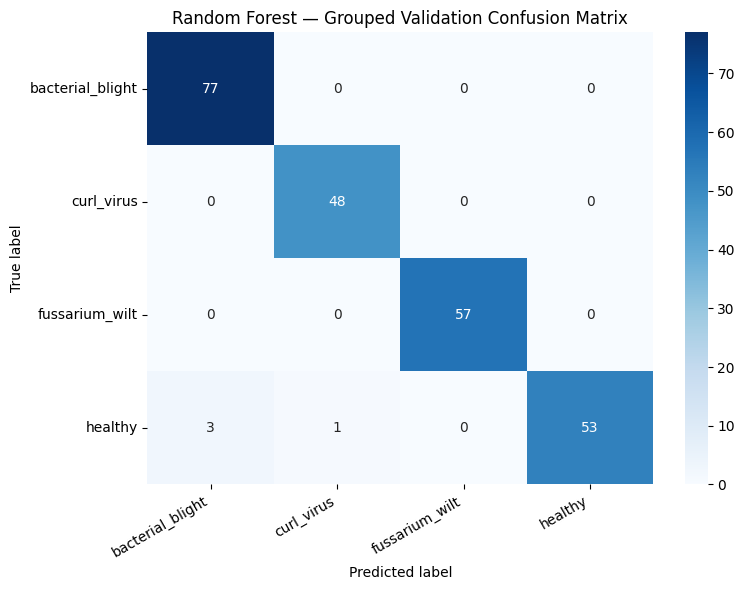

                  precision    recall  f1-score   support

bacterial_blight       0.96      1.00      0.98        77
      curl_virus       0.98      1.00      0.99        48
  fussarium_wilt       1.00      1.00      1.00        57
         healthy       1.00      0.93      0.96        57

        accuracy                           0.98       239
       macro avg       0.99      0.98      0.98       239
    weighted avg       0.98      0.98      0.98       239



In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

val_predictions = best_model.predict(X_val_new)

class_order = sorted(set(y_train_new))

cm = confusion_matrix(
    y_val_new,
    val_predictions,
    labels=class_order
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Random Forest — Grouped Validation Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_val_new,
    val_predictions,
    labels=class_order,
    zero_division=0
))

Test: features shape = (226, 72)
FINAL TEST RESULTS
Accuracy: 0.9646
Macro Precision: 0.9605
Macro Recall: 0.9567
Macro F1: 0.9583

Classification Report
                  precision    recall  f1-score   support

bacterial_blight       0.99      1.00      0.99        68
      curl_virus       0.98      0.97      0.97        58
  fussarium_wilt       0.95      0.98      0.97        59
         healthy       0.92      0.88      0.90        41

        accuracy                           0.96       226
       macro avg       0.96      0.96      0.96       226
    weighted avg       0.96      0.96      0.96       226



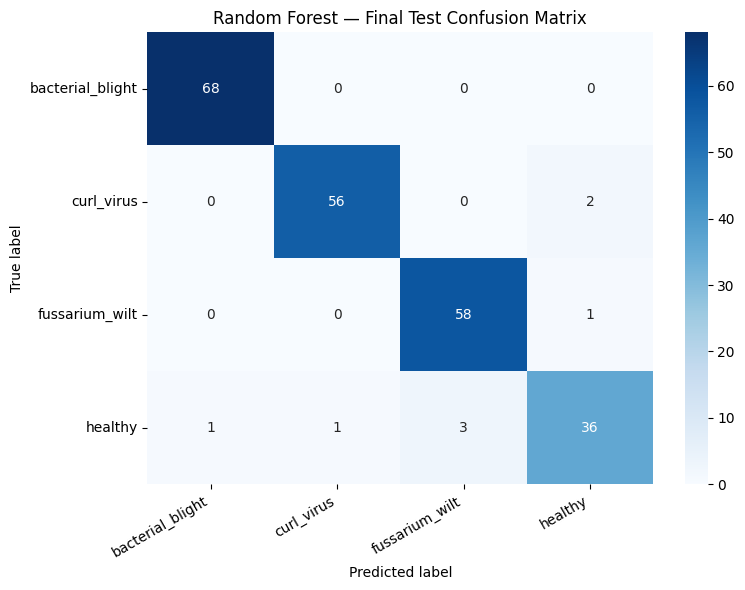

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

X_test_new, y_test_new = build_features(
    test_df_new, "Test"
)

test_predictions = best_model.predict(X_test_new)

test_results = {
    "Accuracy": accuracy_score(y_test_new, test_predictions),
    "Macro Precision": precision_score(
        y_test_new, test_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test_new, test_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test_new, test_predictions,
        average="macro", zero_division=0
    )
}

print("FINAL TEST RESULTS")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

class_order = sorted(set(y_train_new))

print("\nClassification Report")
print(classification_report(
    y_test_new,
    test_predictions,
    labels=class_order,
    zero_division=0
))

cm = confusion_matrix(
    y_test_new,
    test_predictions,
    labels=class_order
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Random Forest — Final Test Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

pd.DataFrame([test_results]).to_csv(
    RESULTS_DIR / "final_test_results.csv",
    index=False
)

In [33]:
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BASE_DIR = Path("/content/drive/MyDrive/CottonGuard-AI")
RESULTS_DIR = BASE_DIR / "results"

train_df_new = pd.read_csv(RESULTS_DIR / "train_grouped.csv")
val_df_new = pd.read_csv(RESULTS_DIR / "validation_grouped.csv")
test_df_new = pd.read_csv(RESULTS_DIR / "test_grouped.csv")

class_names = sorted(train_df_new["label"].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}

print("Classes:", class_to_idx)
print("Train:", len(train_df_new))
print("Validation:", len(val_df_new))
print("Test:", len(test_df_new))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class CottonDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        with Image.open(row["path"]) as image:
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["label"]]
        return image, label

train_dataset = CottonDataset(train_df_new, train_transform)
val_dataset = CottonDataset(val_df_new, eval_transform)
test_dataset = CottonDataset(test_df_new, eval_transform)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Classes: {'bacterial_blight': 0, 'curl_virus': 1, 'fussarium_wilt': 2, 'healthy': 3}
Train: 1126
Validation: 239
Test: 226
Device: cuda
Training batches: 36
Validation batches: 8
Test batches: 8


In [34]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [35]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(class_names))

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Model: ResNet18")
print("Device:", device)
print("Classes:", class_names)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Total parameters:", sum(
    p.numel() for p in model.parameters()
))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Model: ResNet18
Device: cuda
Classes: ['bacterial_blight', 'curl_virus', 'fussarium_wilt', 'healthy']
Trainable parameters: 2052
Total parameters: 11178564


In [36]:
import copy
import torch
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = Path("/content/drive/MyDrive/CottonGuard-AI")
MODELS_DIR = BASE_DIR / "models"
RESULTS_DIR = BASE_DIR / "results"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 10
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    model.train()
    train_loss_total = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)

    train_loss = train_loss_total / len(train_loader.dataset)

    model.eval()
    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets, val_predictions, average="macro"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            MODELS_DIR / "resnet18_best.pth"
        )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

model.load_state_dict(best_state)

history_df = pd.DataFrame(history)
history_df.to_csv(
    RESULTS_DIR / "resnet18_training_history.csv",
    index=False
)

print("\nBest validation loss:", round(best_val_loss, 4))
print("Best model saved to:", MODELS_DIR / "resnet18_best.pth")

Epoch 01/10 | Train Loss: 1.0545 | Val Loss: 0.6437 | Val Accuracy: 0.8410 | Val Macro F1: 0.8434
Epoch 02/10 | Train Loss: 0.5866 | Val Loss: 0.4222 | Val Accuracy: 0.9121 | Val Macro F1: 0.9152
Epoch 03/10 | Train Loss: 0.4334 | Val Loss: 0.3158 | Val Accuracy: 0.9247 | Val Macro F1: 0.9259
Epoch 04/10 | Train Loss: 0.3710 | Val Loss: 0.2862 | Val Accuracy: 0.9582 | Val Macro F1: 0.9604
Epoch 05/10 | Train Loss: 0.3260 | Val Loss: 0.2512 | Val Accuracy: 0.9582 | Val Macro F1: 0.9601
Epoch 06/10 | Train Loss: 0.2864 | Val Loss: 0.2064 | Val Accuracy: 0.9833 | Val Macro F1: 0.9843
Epoch 07/10 | Train Loss: 0.2603 | Val Loss: 0.1962 | Val Accuracy: 0.9623 | Val Macro F1: 0.9627
Epoch 08/10 | Train Loss: 0.2364 | Val Loss: 0.1832 | Val Accuracy: 0.9623 | Val Macro F1: 0.9627
Epoch 09/10 | Train Loss: 0.2251 | Val Loss: 0.1627 | Val Accuracy: 0.9791 | Val Macro F1: 0.9801
Epoch 10/10 | Train Loss: 0.2289 | Val Loss: 0.1442 | Val Accuracy: 0.9874 | Val Macro F1: 0.9881

Best validation los

In [37]:
import torch
import torch.nn as nn
import copy
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = "/content/drive/MyDrive/CottonGuard-AI"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

EPOCHS_FINE = 8
best_val_loss_fine = float("inf")
best_state_fine = copy.deepcopy(model.state_dict())
history_fine = []

for epoch in range(EPOCHS_FINE):
    model.train()
    train_loss_total = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)

    train_loss = train_loss_total / len(train_loader.dataset)

    model.eval()
    val_loss_total = 0.0
    val_predictions, val_targets = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_predictions.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)
    val_acc = accuracy_score(val_targets, val_predictions)
    val_f1 = f1_score(
        val_targets, val_predictions,
        average="macro", zero_division=0
    )

    history_fine.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    if val_loss < best_val_loss_fine:
        best_val_loss_fine = val_loss
        best_state_fine = copy.deepcopy(model.state_dict())

        torch.save(
            best_state_fine,
            f"{MODELS_DIR}/resnet18_finetuned_best.pth"
        )

    print(
        f"Fine-tune Epoch {epoch + 1}/{EPOCHS_FINE} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

model.load_state_dict(best_state_fine)

pd.DataFrame(history_fine).to_csv(
    f"{RESULTS_DIR}/resnet18_finetuning_history.csv",
    index=False
)

print("\nBest fine-tuned validation loss:", round(best_val_loss_fine, 4))
print("Fine-tuned checkpoint saved.")

Fine-tune Epoch 1/8 | Train Loss: 0.1788 | Val Loss: 0.1082 | Val Accuracy: 0.9874 | Val Macro F1: 0.9881
Fine-tune Epoch 2/8 | Train Loss: 0.1211 | Val Loss: 0.0820 | Val Accuracy: 0.9874 | Val Macro F1: 0.9886
Fine-tune Epoch 3/8 | Train Loss: 0.0921 | Val Loss: 0.0621 | Val Accuracy: 0.9916 | Val Macro F1: 0.9924
Fine-tune Epoch 4/8 | Train Loss: 0.0758 | Val Loss: 0.0531 | Val Accuracy: 0.9916 | Val Macro F1: 0.9924
Fine-tune Epoch 5/8 | Train Loss: 0.0625 | Val Loss: 0.0403 | Val Accuracy: 0.9958 | Val Macro F1: 0.9962
Fine-tune Epoch 6/8 | Train Loss: 0.0416 | Val Loss: 0.0367 | Val Accuracy: 0.9958 | Val Macro F1: 0.9962
Fine-tune Epoch 7/8 | Train Loss: 0.0484 | Val Loss: 0.0366 | Val Accuracy: 0.9916 | Val Macro F1: 0.9924
Fine-tune Epoch 8/8 | Train Loss: 0.0344 | Val Loss: 0.0283 | Val Accuracy: 0.9958 | Val Macro F1: 0.9962

Best fine-tuned validation loss: 0.0283
Fine-tuned checkpoint saved.


FINAL RESNET18 TEST RESULTS
Accuracy: 0.9956
Macro Precision: 0.9940
Macro Recall: 0.9957
Macro F1: 0.9948

Classification Report
                  precision    recall  f1-score   support

bacterial_blight       1.00      1.00      1.00        68
      curl_virus       1.00      0.98      0.99        58
  fussarium_wilt       1.00      1.00      1.00        59
         healthy       0.98      1.00      0.99        41

        accuracy                           1.00       226
       macro avg       0.99      1.00      0.99       226
    weighted avg       1.00      1.00      1.00       226



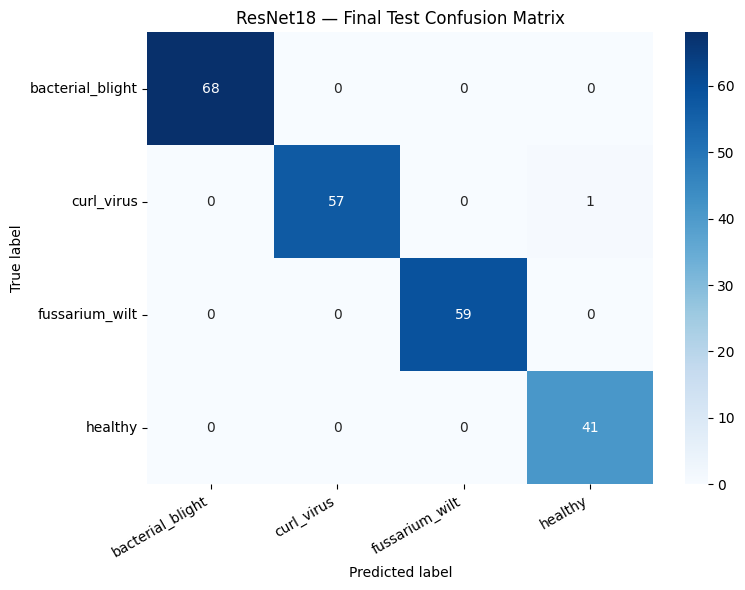

In [38]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from torchvision import models
import torch.nn as nn

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))

checkpoint_path = (
    "/content/drive/MyDrive/CottonGuard-AI/models/"
    "resnet18_finetuned_best.pth"
)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model = model.to(device)
model.eval()

test_predictions = []
test_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_targets.extend(labels.numpy())

test_results = {
    "Accuracy": accuracy_score(test_targets, test_predictions),
    "Macro Precision": precision_score(
        test_targets, test_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        test_targets, test_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        test_targets, test_predictions,
        average="macro", zero_division=0
    )
}

print("FINAL RESNET18 TEST RESULTS")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report")

print(classification_report(
    test_targets,
    test_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("ResNet18 — Final Test Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

pd.DataFrame([test_results]).to_csv(
    "/content/drive/MyDrive/CottonGuard-AI/results/"
    "resnet18_final_test_results.csv",
    index=False
)